# 03a — Frozen local DINOv2 features from padded text boxes


Discover caches and define the crop contract. Padding means a fraction of the ORIGINAL width/height added on EACH side. No model loads on a cache hit.


In [1]:
from pathlib import Path
import os
os.environ['HF_HUB_OFFLINE'] = '1'
import json
import hashlib
import torch
from PIL import Image
from config import CONFIG, ROOT, fingerprint, model_files, require_cache, reuse_base_caches
from crop_features import padded_bounds, prepare_crop
reuse_base_caches()
CACHE = CONFIG['cache_dir']
require_cache(CACHE / 'sequences.json', '01_prepare_sequence_cache.ipynb')
sequences = json.loads((CACHE / 'sequences.json').read_text(encoding='utf-8'))
MODEL_PATH = Path(CONFIG['dino_model'])
assert MODEL_PATH.is_dir(), f'Missing locally downloaded DINOv2: {MODEL_PATH}'
assert CONFIG['crop_padding'] >= 0
FEATURE_CONFIG = {'encoder': 'dinov2', 'model': str(MODEL_PATH), 'model_files': model_files(MODEL_PATH),
    'padding_per_side': CONFIG['crop_padding'], 'image_size': CONFIG['crop_image_size'],
    'resize': 'fit_white_square_no_center_crop', 'color': 'RGB', 'pool': 'CLS', 'feature_dim': 384,
    'processor': 'local_slow_processor_normalization',
    'helper_sha256': hashlib.sha256((ROOT / 'crop_features.py').read_bytes()).hexdigest()}
signature = fingerprint({'sequences': sequences, 'feature_config': FEATURE_CONFIG})
FEATURES = CACHE / 'dino.pt'
saved = torch.load(FEATURES, map_location='cpu', weights_only=True) if FEATURES.exists() else None
reuse = bool(saved and saved['signature'] == signature)
print('Local encoder:', MODEL_PATH)
print('Padding per side:', CONFIG['crop_padding'], '| matching feature cache:', reuse)


Local encoder: C:\MODELS\dinov2-small
Padding per side: 0.2 | matching feature cache: False


Preview padded crops before feature extraction. The red rectangle marks the ORIGINAL text box inside the crop. Set SHOW_PREVIEW to True to inspect even when the feature cache exists.


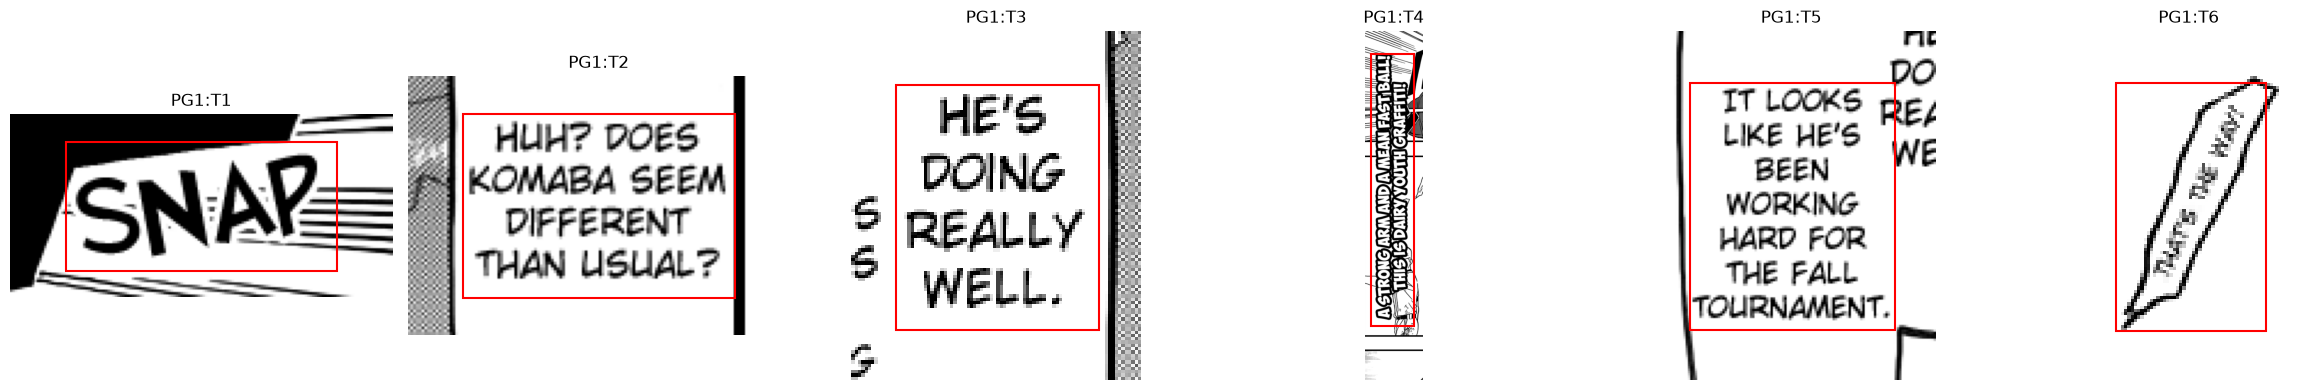

In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
SHOW_PREVIEW = not reuse
if SHOW_PREVIEW:
    examples = [(seq, box) for seq in sequences for box in seq['boxes']][:6]
    if examples:
        fig, axes = plt.subplots(1, len(examples), figsize=(4*len(examples), 4), squeeze=False)
        for ax, (seq, box) in zip(axes[0], examples):
            page = seq['pages'][box['page_index']]
            with Image.open(page['path']) as image:
                bounds = padded_bounds(box['bbox'], image.size, CONFIG['crop_padding'])
                crop = image.convert('RGB').crop(bounds)
            x1, y1, x2, y2 = box['bbox']
            ax.imshow(crop)
            ax.add_patch(patches.Rectangle((x1-bounds[0], y1-bounds[1]), x2-x1, y2-y1,
                                           edgecolor='red', facecolor='none', linewidth=1.5))
            ax.set_title(box['box_id'])
            ax.axis('off')
        fig.tight_layout()
        plt.show()


Create only missing features with the frozen local model. Each completed sequence is cached so interrupted extraction can resume. The image processor only normalizes our prepared squares; it does not crop away borders.


In [3]:
if not reuse:
    from transformers import AutoImageProcessor, AutoModel
    from tqdm.auto import tqdm
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    processor = AutoImageProcessor.from_pretrained(str(MODEL_PATH), local_files_only=True, use_fast=False)
    model = AutoModel.from_pretrained(str(MODEL_PATH), local_files_only=True).to(device).eval()
    model.requires_grad_(False)
    assert model.config.hidden_size == 384, 'This experiment expects the local DINOv2-small encoder.'
    assert CONFIG['crop_image_size'] % model.config.patch_size == 0
    sequence_cache = CACHE / 'dino_sequences'
    sequence_cache.mkdir(exist_ok=True)
    vectors, audits = {}, {}
    try:
        with torch.inference_mode():
            for seq in tqdm(sequences, desc='Padded DINO crops'):
                sid = seq['sequence_id']
                key = fingerprint({'sequence': seq, 'feature_config': FEATURE_CONFIG})
                sequence_file = sequence_cache / f'{key}.pt'
                if sequence_file.exists():
                    result = torch.load(sequence_file, map_location='cpu', weights_only=True)
                else:
                    result = {'vectors': {}, 'bounds': {}}
                    # Process page-by-page so only a small batch of RGB crops is kept in memory.
                    for page_index, page in enumerate(seq['pages']):
                        page_boxes = [b for b in seq['boxes'] if b['page_index'] == page_index]
                        with Image.open(page['path']) as image:
                            image = image.convert('RGB')
                            size = CONFIG['crop_batch_size']
                            for start in range(0, len(page_boxes), size):
                                batch_boxes = page_boxes[start:start+size]
                                crops, bounds = [], []
                                for box in batch_boxes:
                                    crop, expanded = prepare_crop(image, box['bbox'], CONFIG['crop_padding'], CONFIG['crop_image_size'])
                                    crops.append(crop)
                                    bounds.append(expanded)
                                inputs = processor(images=crops, return_tensors='pt', do_resize=False, do_center_crop=False)
                                hidden = model(**{k: v.to(device) for k, v in inputs.items()}).last_hidden_state
                                # CLS gives one 384-dimensional descriptor for each entire padded crop.
                                pooled = hidden[:, 0].float().cpu()
                                assert pooled.shape == (len(batch_boxes), 384) and torch.isfinite(pooled).all()
                                for box, vector, expanded in zip(batch_boxes, pooled, bounds):
                                    result['vectors'][box['box_id']] = vector.clone()
                                    result['bounds'][box['box_id']] = list(expanded)
                    torch.save(result, sequence_file)
                assert set(result['vectors']) == {b['box_id'] for b in seq['boxes']}
                vectors[sid], audits[sid] = result['vectors'], result['bounds']
        saved = {'signature': signature, 'feature_config': FEATURE_CONFIG, 'vectors': vectors, 'bounds': audits}
        torch.save(saved, FEATURES)
    finally:
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
print('DINO features:', FEATURES, '| sequences:', len(saved['vectors']))


Padded DINO crops:   0%|          | 0/80 [00:00<?, ?it/s]

DINO features: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationImbalanceTrainingPaddedBox\cache\dino.pt | sequences: 80
